In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/employee_salary_analysis_30.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (31, 6)


,Employee_ID,Department,Designation,Experience_Years,Education,Salary
0,1001,Engineering,Software Engineer,2.0,Bachelor's,72000.0
1,1002,Human Resources,HR Executive,3.0,Bachelor's,48000.0
2,1003,Finance,Financial Analyst,4.0,Master's,68000.0
3,1004,Marketing,Marketing Executive,1.0,Bachelor's,42000.0
4,1005,Engineering,Data Analyst,3.0,Bachelor's,65000.0


In [2]:
print("Total rows and columns:", df.shape)

print("\nAll departments:")
print(df["Department"].unique())

print("\nAll employee records:")
display(df)

Total rows and columns: (31, 6)

All departments:
['Engineering' 'Human Resources' 'Finance' 'Marketing' 'Sales']

All employee records:


,Employee_ID,Department,Designation,Experience_Years,Education,Salary
0,1001,Engineering,Software Engineer,2.0,Bachelor's,72000.0
1,1002,Human Resources,HR Executive,3.0,Bachelor's,48000.0
2,1003,Finance,Financial Analyst,4.0,Master's,68000.0
3,1004,Marketing,Marketing Executive,1.0,Bachelor's,42000.0
4,1005,Engineering,Data Analyst,3.0,Bachelor's,65000.0
5,1006,Sales,Sales Executive,2.0,Bachelor's,46000.0
6,1007,Engineering,Senior Software Engineer,7.0,Master's,112000.0
7,1008,Finance,Accountant,5.0,Bachelor's,61000.0
8,1009,Human Resources,Recruiter,2.0,Bachelor's,45000.0
9,1010,Marketing,Marketing Manager,8.0,Master's,98000.0


In [3]:
# 1. Check dataset information
print("Dataset Information:")
df.info()

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Get statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Employee_ID       31 non-null     int64  
 1   Department        31 non-null     object 
 2   Designation       31 non-null     object 
 3   Experience_Years  30 non-null     float64
 4   Education         30 non-null     object 
 5   Salary            30 non-null     float64
dtypes: float64(2), int64(1), object(3)
memory usage: 1.6+ KB

Missing Values:
Employee_ID         0
Department          0
Designation         0
Experience_Years    1
Education           1
Salary              1
dtype: int64

Duplicate Rows: 1

Statistical Summary:


,Employee_ID,Experience_Years,Salary
count,31.000000,30.000000,30.000000
mean,1015.161290,4.033333,68400.000000
std,8.858505,2.484203,21991.534421
min,1001.000000,1.000000,39000.000000
25%,1007.500000,2.000000,51500.000000
50%,1015.000000,3.000000,61500.000000
75%,1022.500000,5.000000,84250.000000
max,1030.000000,10.000000,118000.000000


In [4]:
# Step 1: Remove duplicate rows
df = df.drop_duplicates()

# Step 2: Fill missing experience with the median
df["Experience_Years"] = df["Experience_Years"].fillna(
    df["Experience_Years"].median()
)

# Step 3: Fill missing education with the most common value
df["Education"] = df["Education"].fillna(
    df["Education"].mode()[0]
)

# Step 4: Fill missing salary with the median salary
df["Salary"] = df["Salary"].fillna(
    df["Salary"].median()
)

# Step 5: Verify the cleaning
print("Dataset shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())

display(df.head())

Dataset shape after cleaning: (30, 6)

Missing values after cleaning:
Employee_ID         0
Department          0
Designation         0
Experience_Years    0
Education           0
Salary              0
dtype: int64

Duplicate rows after cleaning: 0


,Employee_ID,Department,Designation,Experience_Years,Education,Salary
0,1001,Engineering,Software Engineer,2.0,Bachelor's,72000.0
1,1002,Human Resources,HR Executive,3.0,Bachelor's,48000.0
2,1003,Finance,Financial Analyst,4.0,Master's,68000.0
3,1004,Marketing,Marketing Executive,1.0,Bachelor's,42000.0
4,1005,Engineering,Data Analyst,3.0,Bachelor's,65000.0


In [5]:
# 1. Overall salary statistics
print("Average Salary:", round(df["Salary"].mean(), 2))
print("Median Salary:", df["Salary"].median())
print("Minimum Salary:", df["Salary"].min())
print("Maximum Salary:", df["Salary"].max())

# 2. Average salary by department
print("\nAverage Salary by Department:")
dept_salary = df.groupby("Department")["Salary"].mean().sort_values(
    ascending=False
)
display(dept_salary)

# 3. Average salary by designation
print("\nAverage Salary by Designation:")
job_salary = df.groupby("Designation")["Salary"].mean().sort_values(
    ascending=False
)
display(job_salary)

# 4. Average salary by experience
print("\nAverage Salary by Experience:")
exp_salary = df.groupby("Experience_Years")["Salary"].mean().sort_index()
display(exp_salary)

Average Salary: 68266.67
Median Salary: 61000.0
Minimum Salary: 39000.0
Maximum Salary: 118000.0

Average Salary by Department:


,Salary
Department,
Engineering,76222.222222
Finance,71833.333333
Sales,66200.000000
Marketing,61600.000000
Human Resources,58400.000000



Average Salary by Designation:


,Salary
Designation,
Finance Manager,118000.000000
Senior Software Engineer,112000.000000
Marketing Manager,98000.000000
Sales Manager,96500.000000
Data Scientist,96000.000000
HR Manager,92000.000000
DevOps Engineer,85000.000000
Cloud Engineer,78000.000000
Financial Analyst,75000.000000



Average Salary by Experience:


,Salary
Experience_Years,
1.0,46333.333333
2.0,53000.000000
3.0,58142.857143
4.0,66400.000000
5.0,78500.000000
6.0,85000.000000
7.0,112000.000000
8.0,98000.000000
9.0,98500.000000


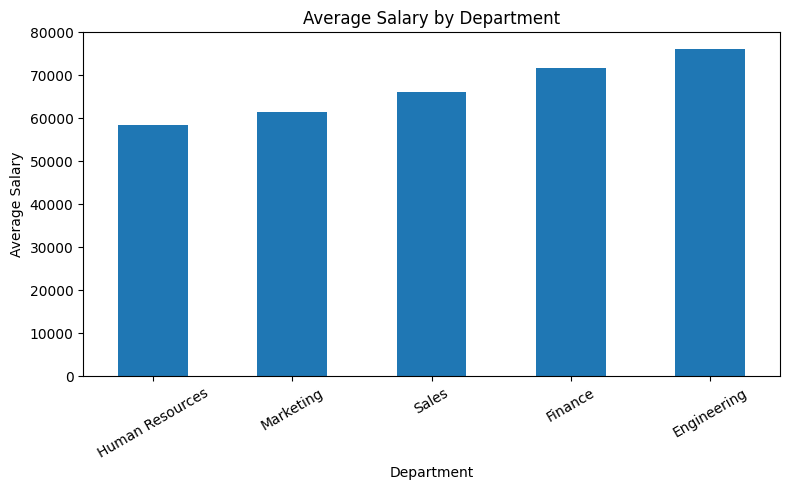

In [6]:
dept_salary = df.groupby("Department")["Salary"].mean().sort_values()

dept_salary.plot(kind="bar", figsize=(8, 5))

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

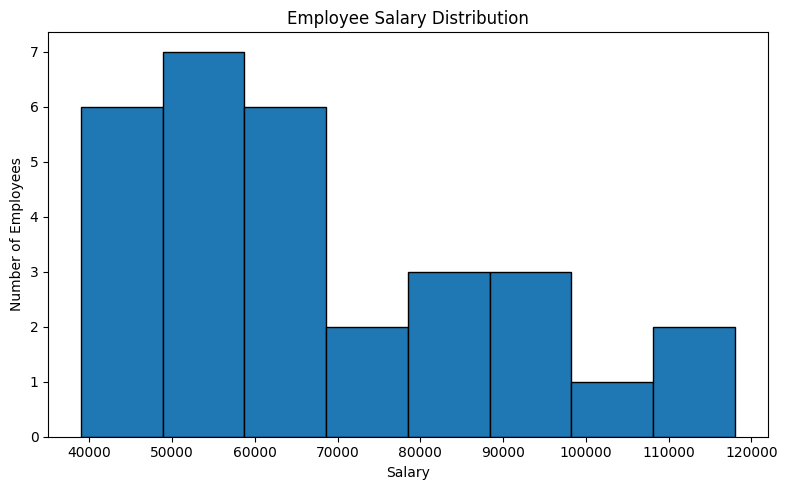

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df["Salary"], bins=8, edgecolor="black")

plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

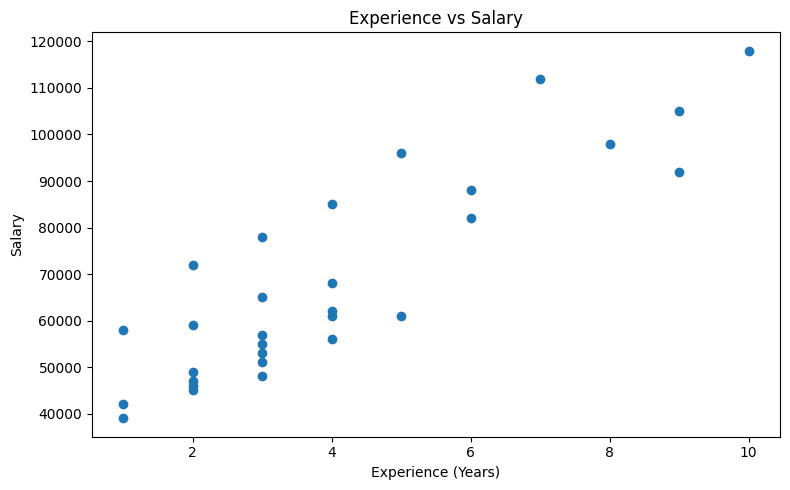

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Experience_Years"], df["Salary"])

plt.title("Experience vs Salary")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()

In [9]:
print("===== EMPLOYEE SALARY ANALYSIS =====")

print("\n1. Total Employees:", len(df))

print("2. Average Salary: ₹{:,.2f}".format(df["Salary"].mean()))

print("3. Highest Salary: ₹{:,.0f}".format(df["Salary"].max()))

print("4. Lowest Salary: ₹{:,.0f}".format(df["Salary"].min()))

highest_dept = df.groupby("Department")["Salary"].mean().idxmax()
highest_avg = df.groupby("Department")["Salary"].mean().max()

print("5. Highest Paying Department:", highest_dept)
print("   Average Salary: ₹{:,.2f}".format(highest_avg))

correlation = df["Experience_Years"].corr(df["Salary"])
print("6. Experience-Salary Correlation: {:.2f}".format(correlation))

===== EMPLOYEE SALARY ANALYSIS =====

1. Total Employees: 30
2. Average Salary: ₹68,266.67
3. Highest Salary: ₹118,000
4. Lowest Salary: ₹39,000
5. Highest Paying Department: Engineering
   Average Salary: ₹76,222.22
6. Experience-Salary Correlation: 0.88
